# Baseline model — Uni-Sign + retrieval, on our Thai data

Reference point for v10 and later versions (report / research). **Baseline** = the original Uni-Sign pose encoder (ICLR 2025, WLASL
checkpoint), frozen, used as a feature extractor + nearest-neighbour search in a bank of Thai clips.
**Adapted** = the same plus a light residual adapter trained on our train signers. No tagger, spotting model, calibration or language
layer. Files: `models/baseline-model/` (architecture figures in `figures/`).

In [1]:
import sys, json, numpy as np, pandas as pd
from pathlib import Path
ROOT = Path.cwd(); HERE = ROOT / "models" / "baseline-model"
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(HERE))
from baseline import Baseline, canon_fn, score_video
from evalsets import DATA_TEST, IPHONE
from modules.encoder import concept_scores, retrieval_metrics

## 0. Architecture
Figures in `models/baseline-model/figures/` (PNG + SVG): the original Uni-Sign pose encoder, one part branch, the baseline pipeline (vs what v8–v10 add), and the input keypoint parts.

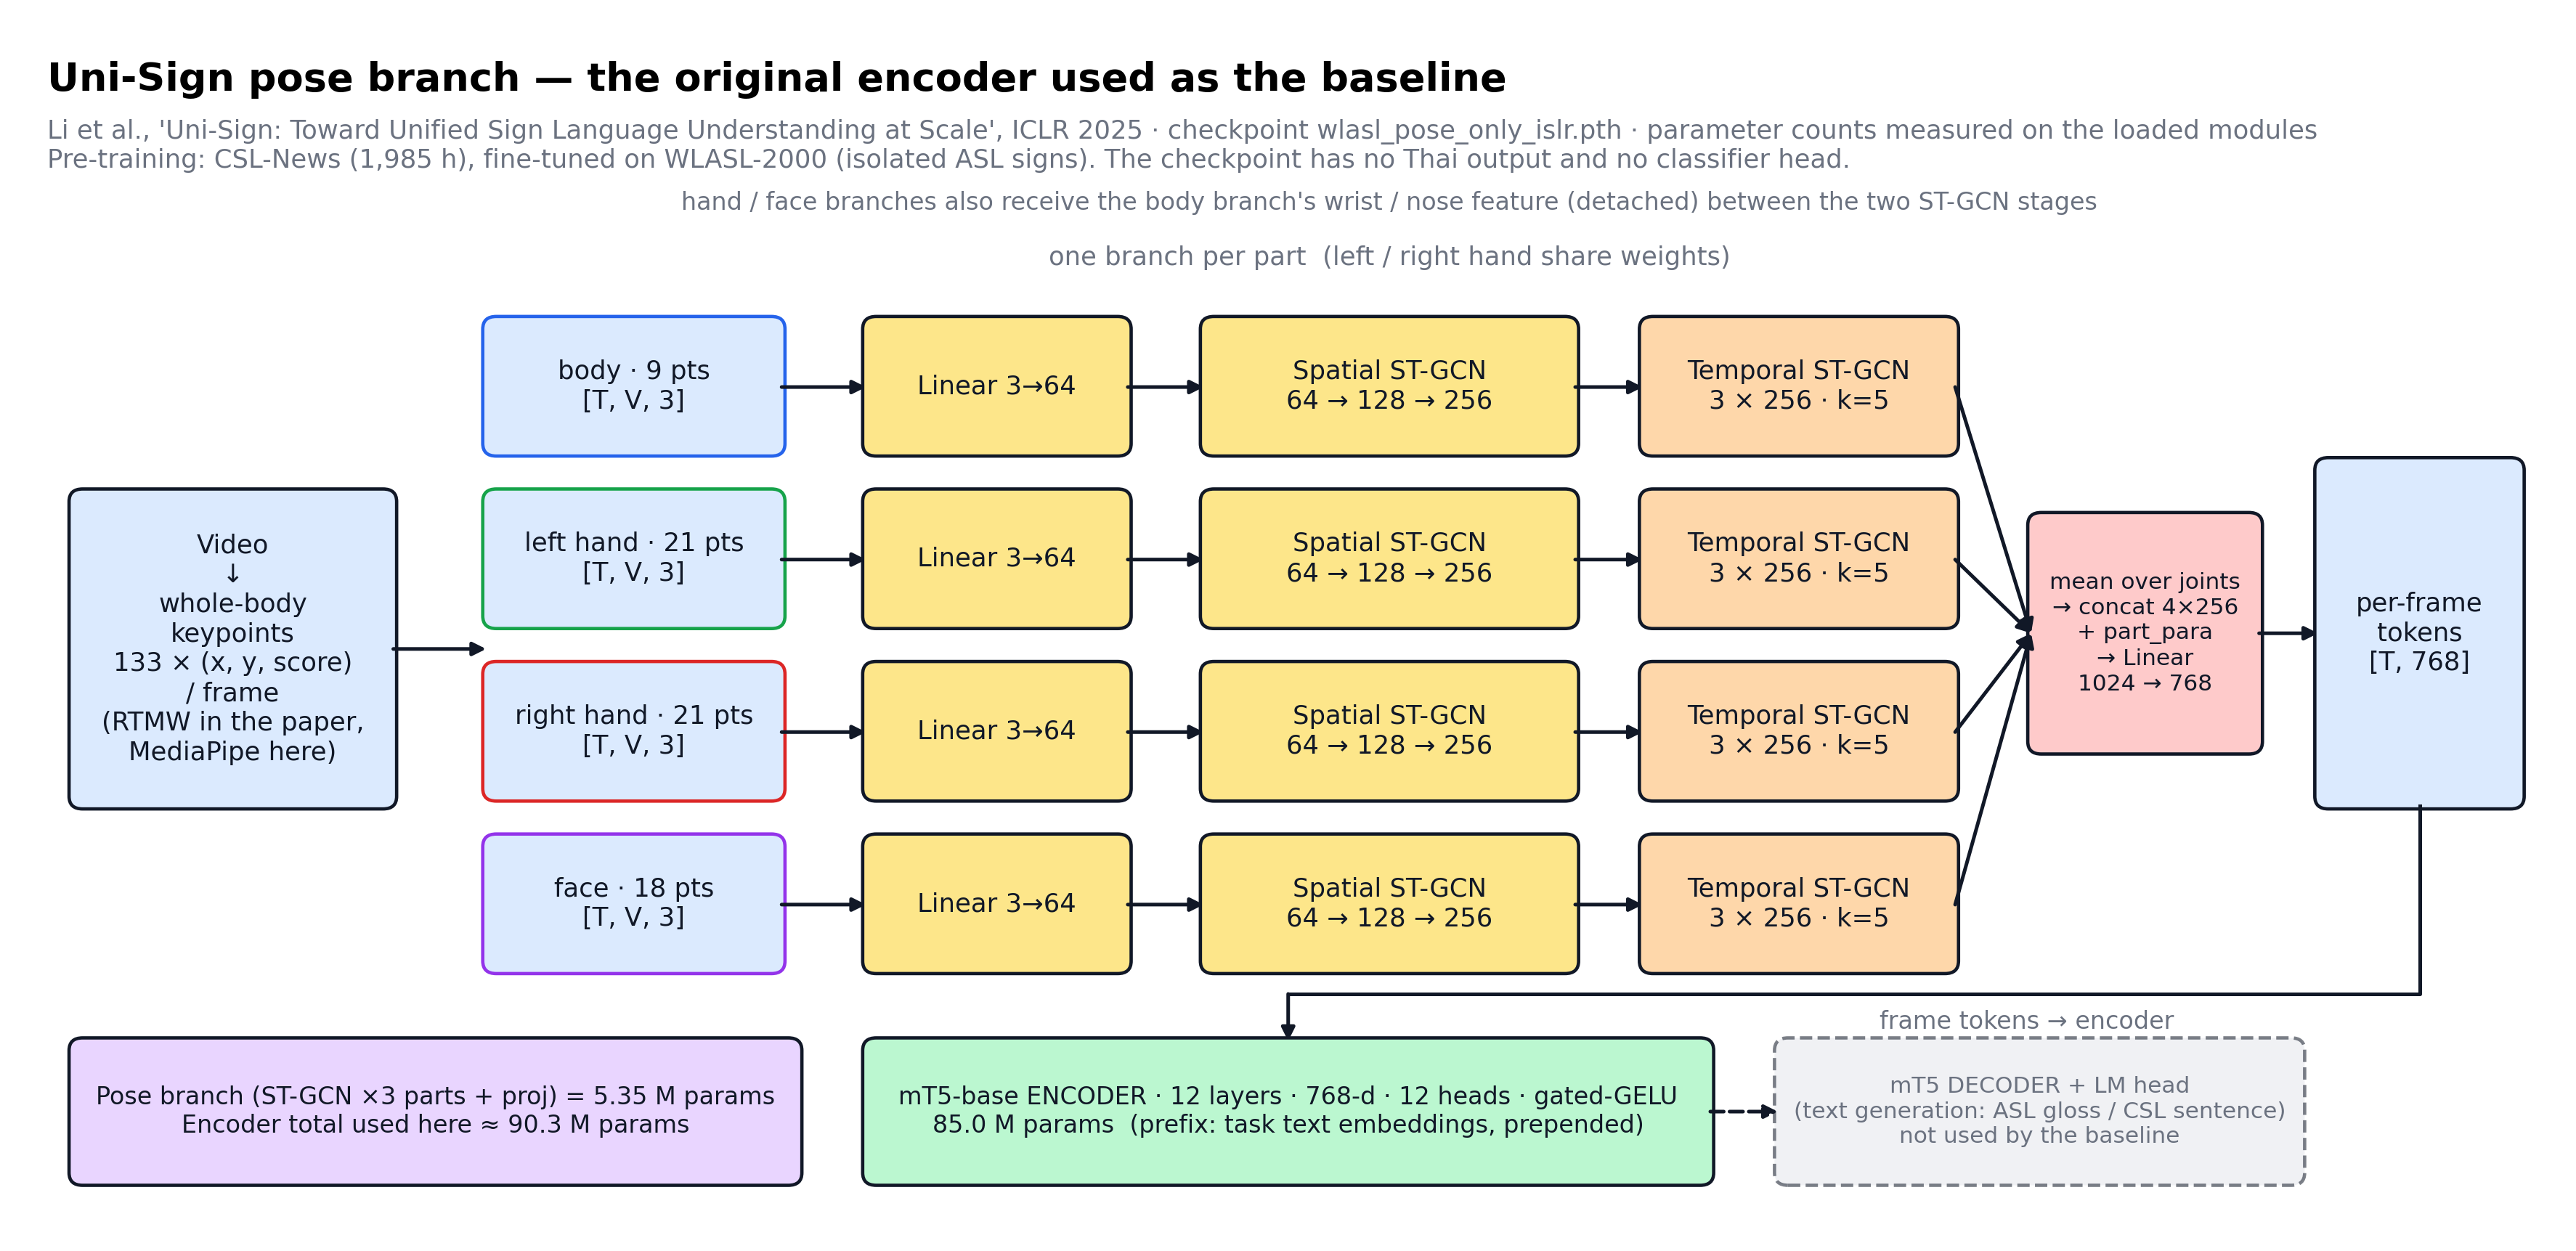

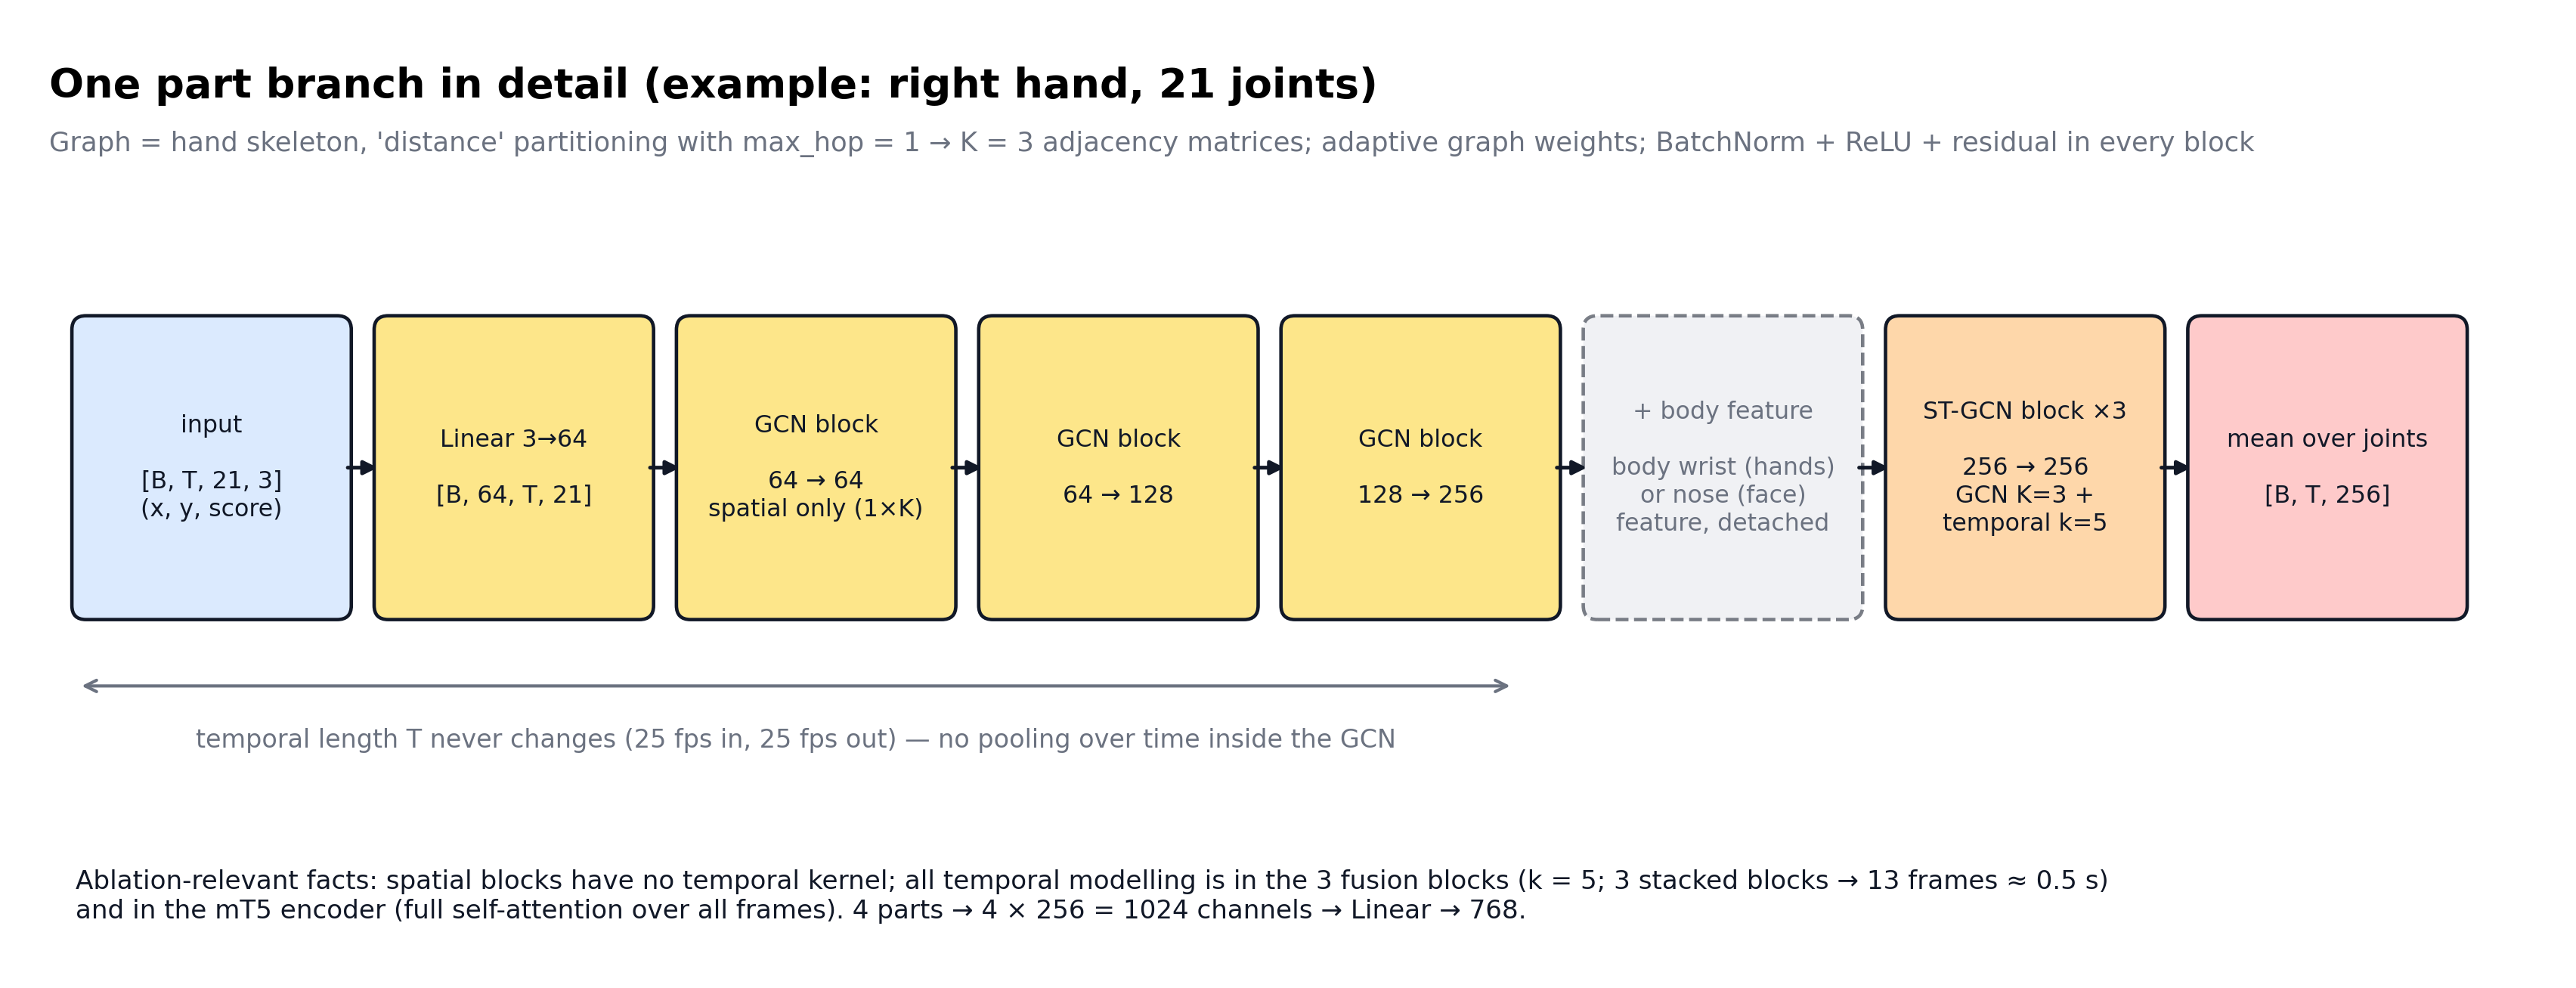

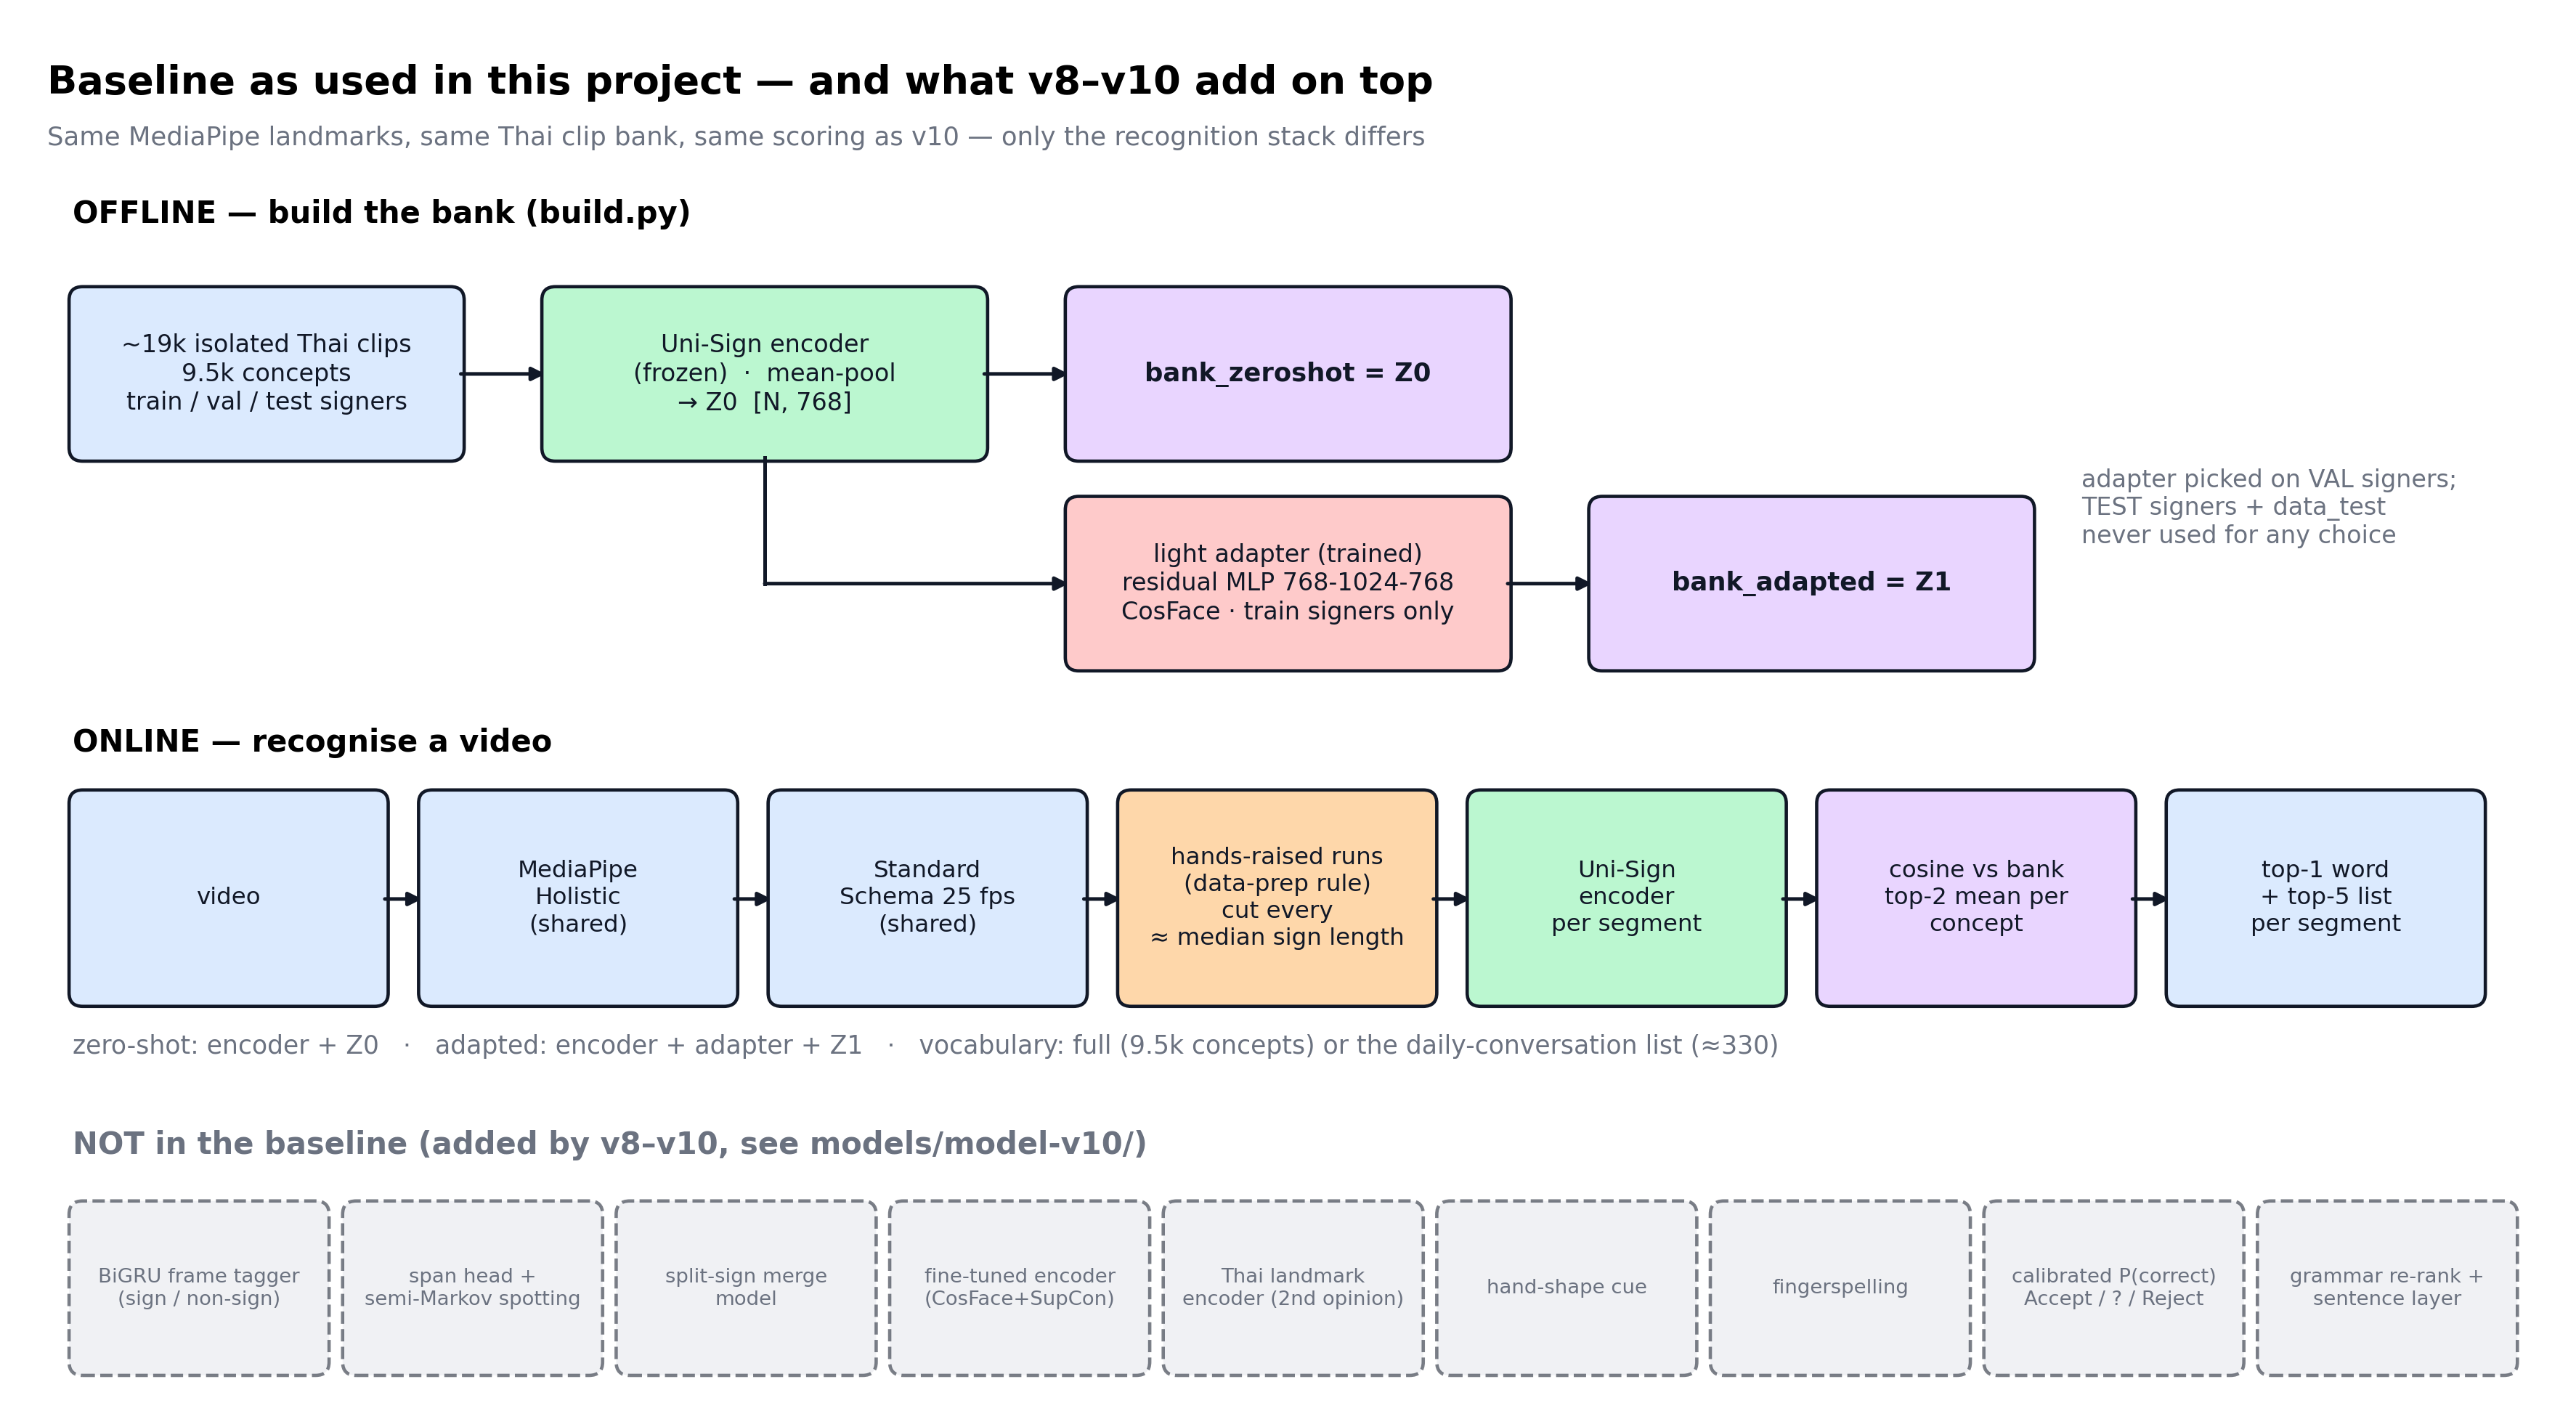

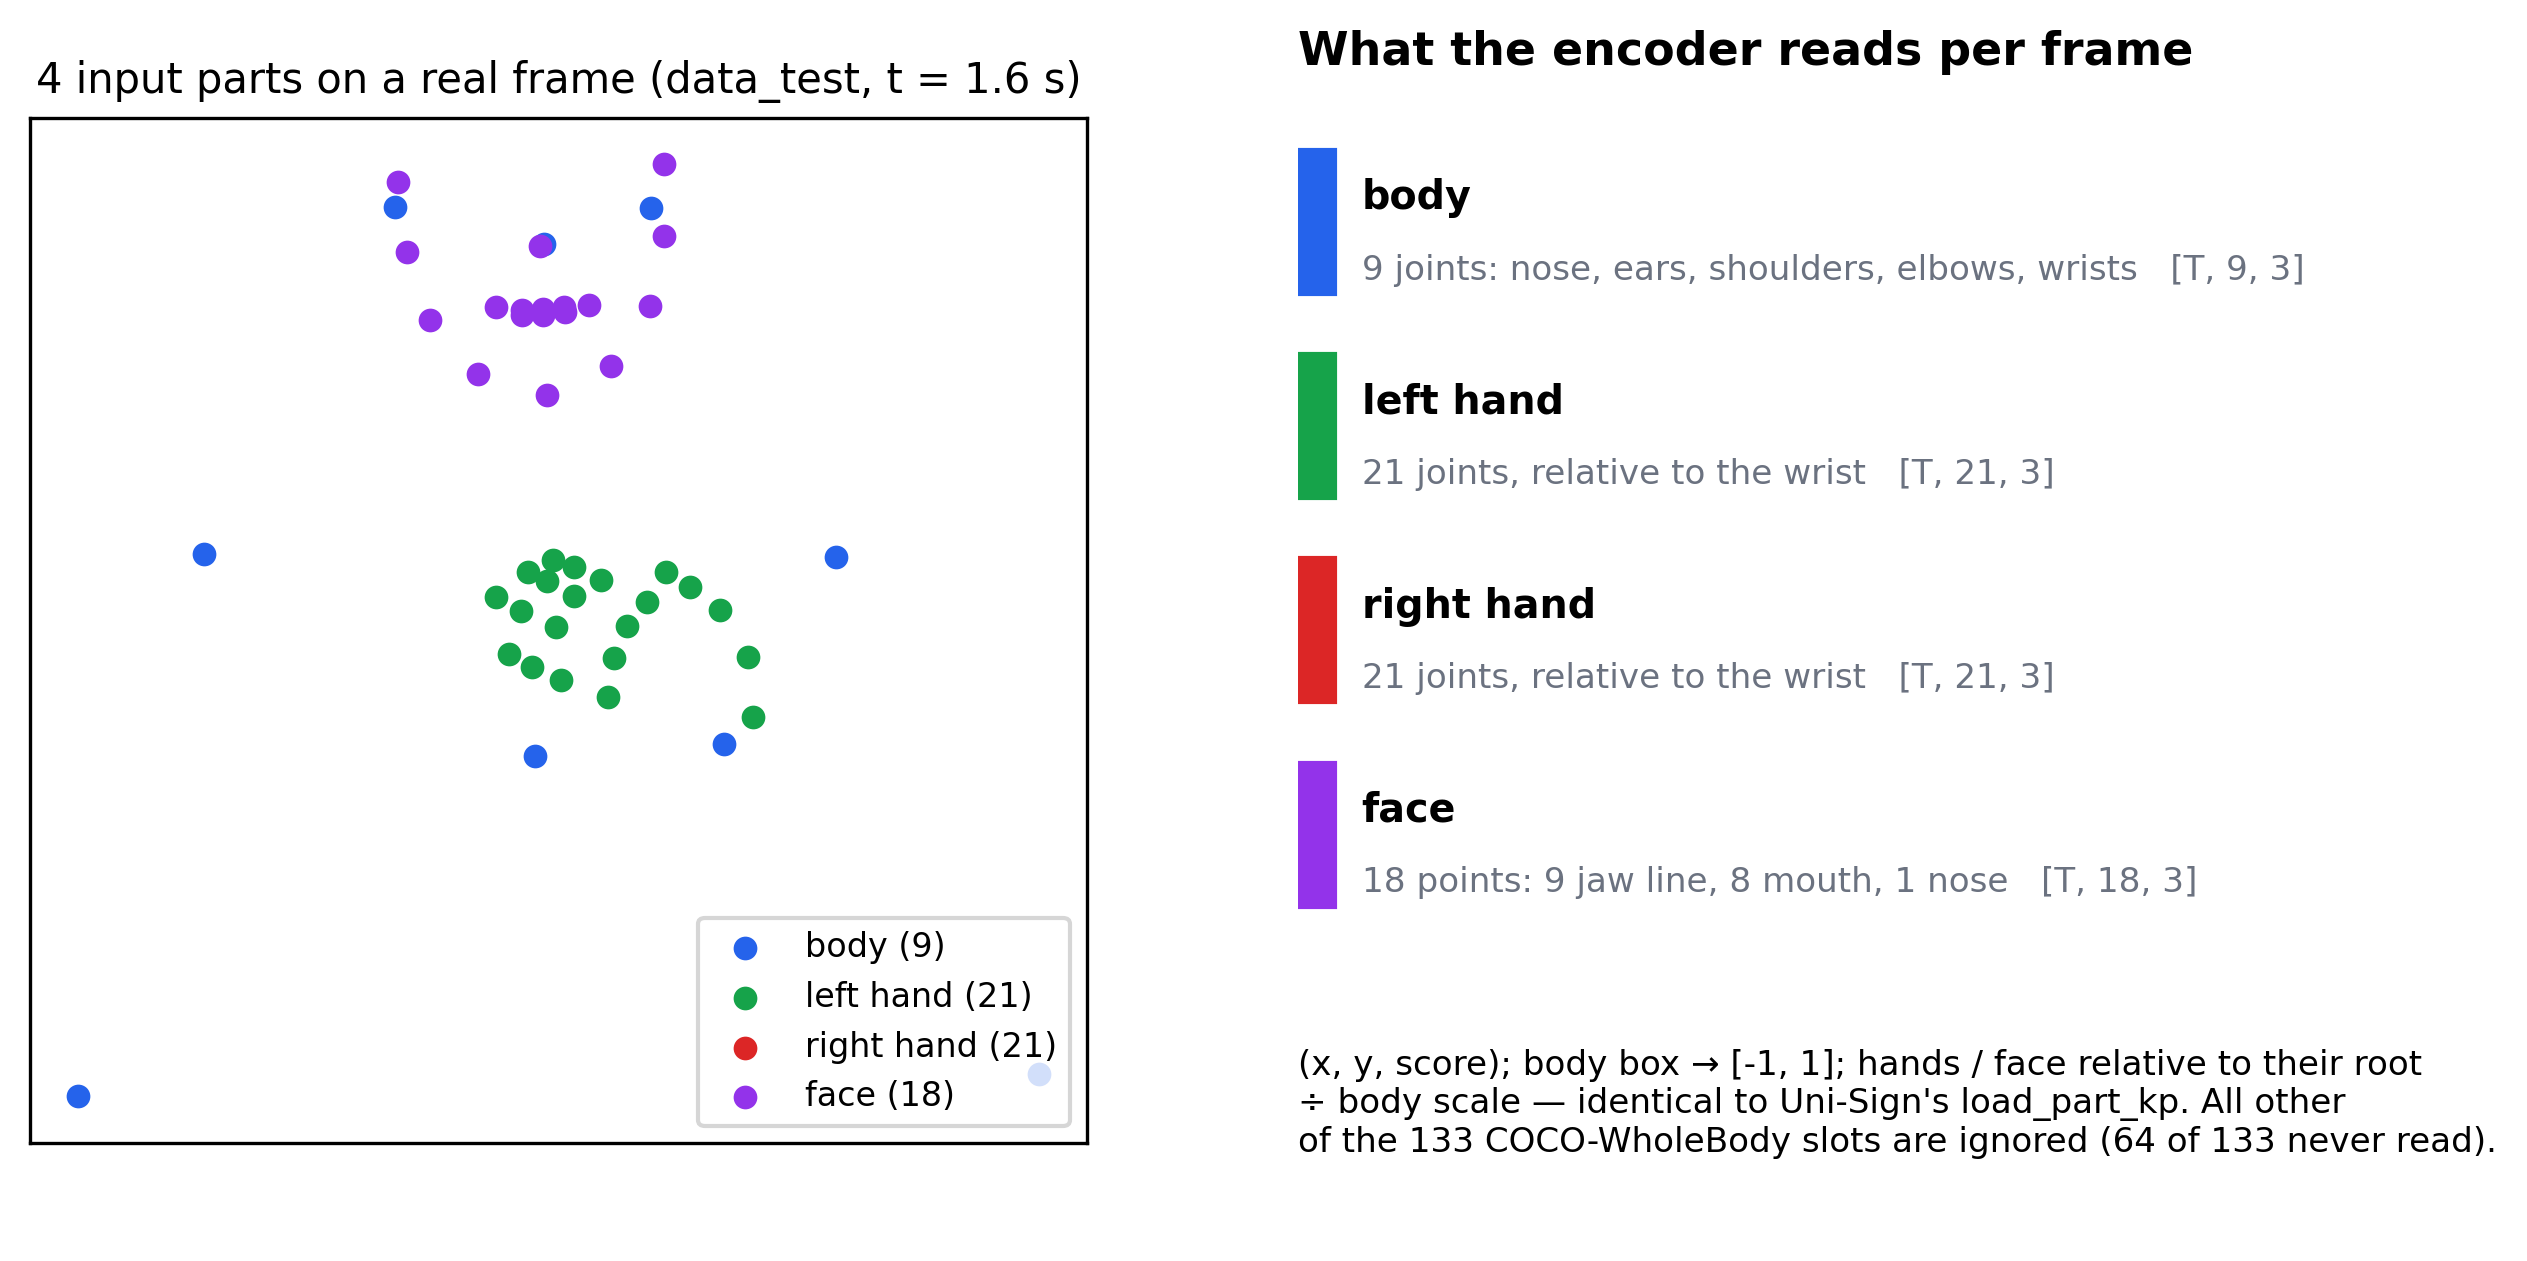

In [2]:
from IPython.display import Image, display
for f in ("fig1_unisign_pose_architecture", "fig2_part_branch_stgcn", "fig3_baseline_pipeline", "fig4_input_keypoint_parts"):
    display(Image(filename=str(HERE / "figures" / f"{f}.png"), width=900))

## 1. Isolated words, held-out signers (test role)
Bank = train signers only; query = a signer never seen in training. Open vocabulary (≈9.5k concepts).

In [3]:
z = np.load(HERE / "bank.npz", allow_pickle=True)
c, role, ds = z["concept"], z["role"], z["dataset"]; tr = role == "train"; n_c = len(z["concepts"])
rows = []
for name, Z in (("baseline (zero-shot)", z["Z0"]), ("baseline + adapter", z["Z1"])):
    Z = Z.astype(np.float32)
    for d in ("ttrs", "tslone", "th_sl"):
        q = (role == "test") & (ds == d)
        m = retrieval_metrics(concept_scores(Z[q], Z[tr], c[tr], n_c), c[q])
        rows.append(dict(model=name, test_set=d, n=m["n"], R1=m["R1"], R5=m["R5"], MRR=m["MRR"]))
iso = pd.DataFrame(rows).round(3); iso.pivot(index="test_set", columns="model", values=["R1", "R5", "MRR"])

R1                                      R5  \
model    baseline (zero-shot) baseline + adapter baseline (zero-shot)   
test_set                                                                
th_sl                   0.081              0.098                0.224   
tslone                  0.797              0.869                0.936   
ttrs                    0.143              0.190                0.345   

                                             MRR                     
model    baseline + adapter baseline (zero-shot) baseline + adapter  
test_set                                                             
th_sl                 0.234                0.150              0.163  
tslone                0.960                0.862              0.913  
ttrs                  0.405                0.237              0.276

## 2. data_test (continuous videos, 22 reference words)
Same landmarks and scorer as `python main.py test`. Recall@1/@5: reference word is the top-1 / in the top-5 of some segment. Vocabulary: daily conversation (v10's default) or full.

In [4]:
from modules.mediapipe_pose import load_raw
canon = canon_fn(); out = {}
for variant in ("zeroshot", "adapted"):
    for vocab in ("daily", "full"):
        b = Baseline(variant, vocab=vocab); bv = {b.concepts[i] for i in set(b.inst_c) if b.allowed[i]}
        out[(variant, vocab)] = {k: score_video(b.recognise_landmarks(load_raw(p)), ref, canon, bv) for k, (p, ref) in DATA_TEST.items()}
v10 = json.load(open(HERE / "results" / "v10_reference.json", encoding="utf8"))["results"]
def avg(r): return {m: np.mean([x[m] for x in r.values()]) for m in ("r1", "r5", "wer", "count_err")}
tab = {"baseline (zero-shot)": avg(out[("zeroshot", "daily")]), "baseline + adapter": avg(out[("adapted", "daily")]), "v10": avg(v10["conversation"])}
tab_full = {"baseline (zero-shot)": avg(out[("zeroshot", "full")]), "baseline + adapter": avg(out[("adapted", "full")]), "v10": avg(v10["full"])}
print("daily-conversation vocabulary"); display(pd.DataFrame(tab).T.round(3))
print("full vocabulary");               display(pd.DataFrame(tab_full).T.round(3))

C:\Users\BM MONEY\miniconda3\envs\hugging\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


daily-conversation vocabulary


,r1,r5,wer,count_err
baseline (zero-shot),0.282,0.658,0.808,0.8
baseline + adapter,0.282,0.658,0.808,0.8
v10,0.540,0.725,0.724,0.8


full vocabulary


,r1,r5,wer,count_err
baseline (zero-shot),0.187,0.244,0.903,0.8
baseline + adapter,0.174,0.311,0.876,0.8
v10,0.492,0.639,0.743,0.6


Per video (daily vocabulary): reference vs what each system said.

In [5]:
rows = []
for k in DATA_TEST:
    r = out[("zeroshot", "daily")][k]
    rows.append(dict(video=k, reference=" ".join(r["ref"]), zeroshot=" ".join(r["hyp"]), adapted=" ".join(out[("adapted", "daily")][k]["hyp"]),
                     v10=" ".join(v10["conversation"][k]["hyp"])))
pd.DataFrame(rows)

,video,reference,zeroshot,adapted,v10
0,test1,สวัสดี สบายดี ชอบ โกรธ แมว แฟน ปรบมือ,สวัสดี สบายดี ฉัน หก แมว ญาติ แมว,สวัสดี สบายดี ฉัน หก แมว ญาติ แมว,สวัสดี สบายดี ชอบ โกรธ แมว ปิด แมว
1,ฉันปลอบเพื่อนร้องไห้,ฉัน ปลอบใจ เพื่อน ร้องไห้,เพื่อน ด้วยกัน สงสาร สงสาร,เพื่อน ด้วยกัน สงสาร สงสาร,เพื่อน ดู สงสาร
2,ฉันรักเพื่อน,ฉัน รัก เพื่อน,ช่วย,ความรัก,ฉัน รัก
3,พ่อดื่มน้ำ,พ่อ ดื่ม น้ำ,พ่อ รถเมล์ ศูนย์,พ่อ น้า ศูนย์,ศูนย์ พ่อ น้ำ ศูนย์
4,ไปทานข้าวด้วยกันมั้ย,ไป กิน ข้าว ด้วยกัน ไหม,แม่ ด้วยกัน ไป,แม่ ด้วยกัน ไป,คุณ ฉัน กิน ไป


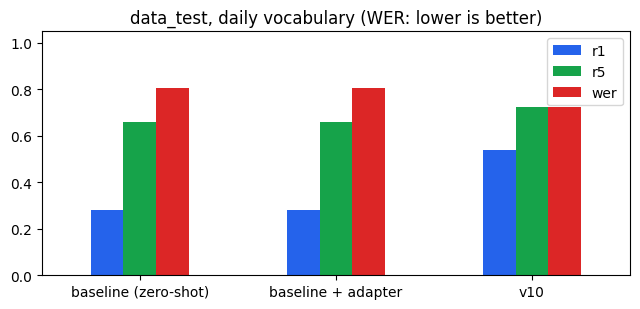

In [6]:
import matplotlib.pyplot as plt
df = pd.DataFrame(tab).T[["r1", "r5", "wer"]]; ax = df.plot.bar(figsize=(6.5, 3.2), rot=0, color=["#2563eb", "#16a34a", "#dc2626"])
ax.set_title("data_test, daily vocabulary (WER: lower is better)"); ax.set_ylim(0, 1.05); plt.tight_layout()
plt.savefig(HERE / "figures" / "results_data_test.png", dpi=200); plt.show()

## 3. Extra: the owner's iPhone recordings (9 words, 5 sentences)

In [7]:
rows = []
for variant in ("zeroshot", "adapted"):
    b = Baseline(variant, vocab="daily"); bv = {b.concepts[i] for i in set(b.inst_c) if b.allowed[i]}
    r = {k: score_video(b.recognise_landmarks(load_raw(p)), ref, canon, bv) for k, (p, ref) in IPHONE.items()}
    for g in ("word", "sentence"):
        rows.append(dict(variant=variant, set=g, **avg({k: v for k, v in r.items() if k.startswith(g)})))
pd.DataFrame(rows).round(3)

,variant,set,r1,r5,wer,count_err
0,zeroshot,word,0.778,0.889,0.444,0.222
1,zeroshot,sentence,0.546,0.677,0.454,1.400
2,adapted,word,0.667,0.889,0.556,0.222
3,adapted,sentence,0.511,0.580,0.489,1.400


## 4. team-drive / Eval-Test / Jack — 5 sentences, frame by frame
Baseline (zero-shot, daily vocabulary). Row = one video: frames along the time axis, below them each predicted segment (green = top-1 is a reference word, amber = only in the top-5, red = miss).

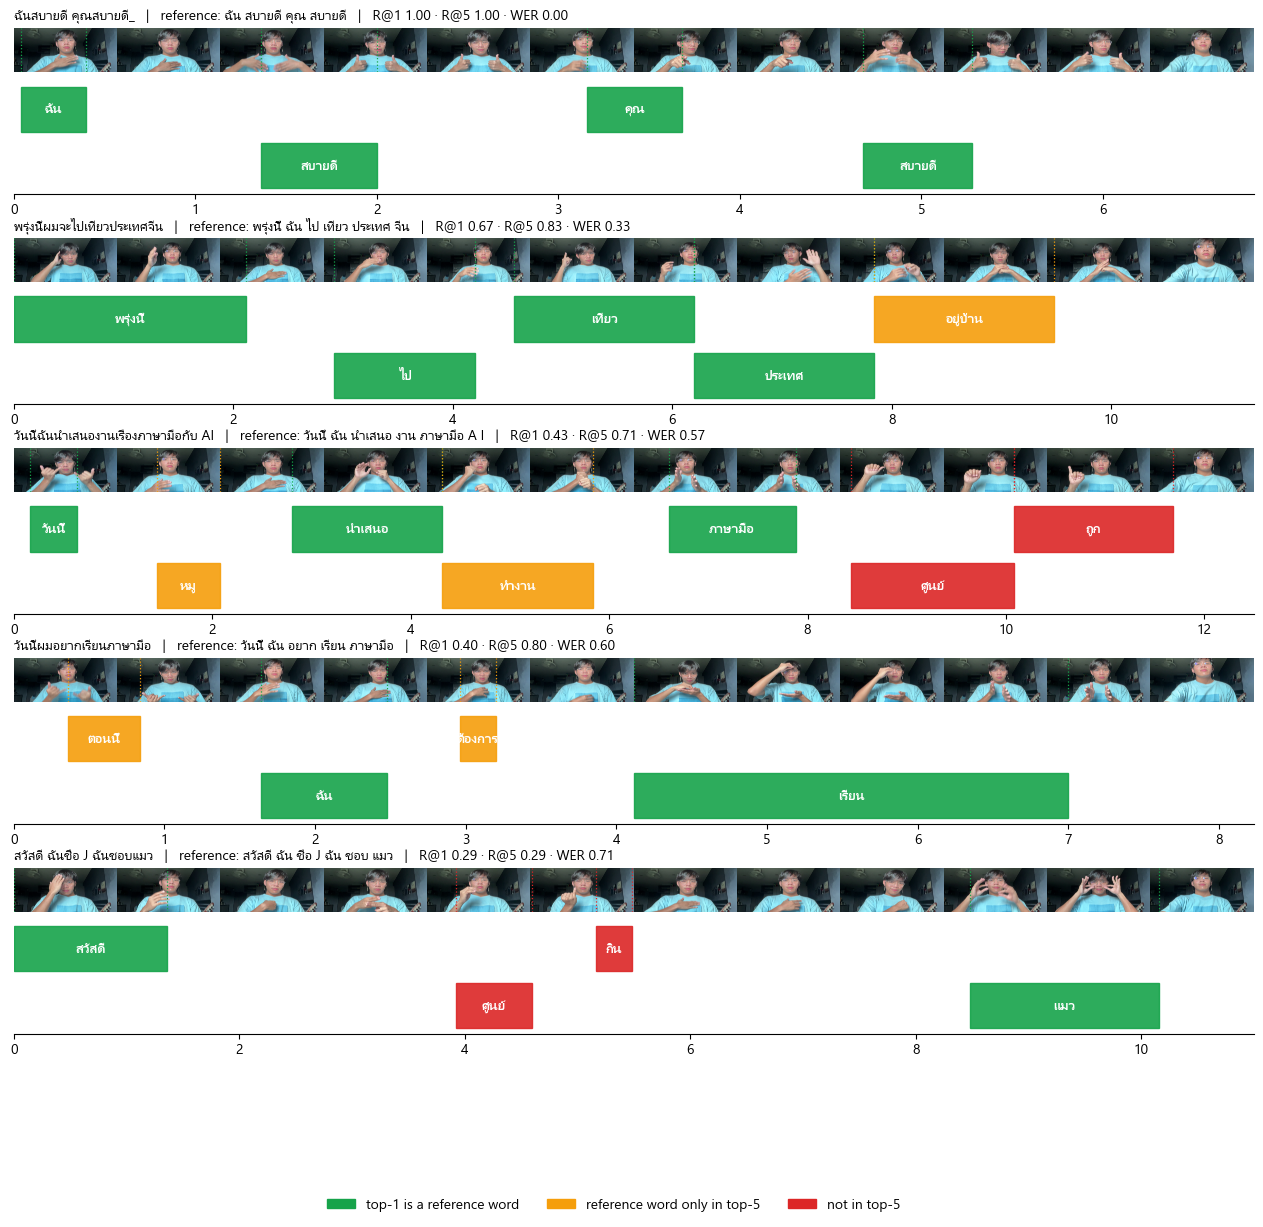

In [8]:
from evalsets import team
from viz import plot_rows
jack = team("Jack"); bz = Baseline("zeroshot", vocab="daily"); bz_vocab = {bz.concepts[i] for i in set(bz.inst_c) if bz.allowed[i]}
seg = {k: bz.recognise_landmarks(load_raw(p)) for k, (p, ref, v) in jack.items()}
res = {k: (seg[k], score_video(seg[k], jack[k][1], canon, bz_vocab)) for k in jack}
plot_rows(jack, res); plt.savefig(HERE / "figures" / "jack_frames.png", dpi=150, bbox_inches="tight"); plt.show()

In [9]:
jr = {}
for variant in ("zeroshot", "adapted"):
    b = Baseline(variant, vocab="daily"); bv = {b.concepts[i] for i in set(b.inst_c) if b.allowed[i]}
    jr[variant] = {k: score_video(b.recognise_landmarks(load_raw(p)), ref, canon, bv) for k, (p, ref, v) in jack.items()}
v10j = {k.replace("Jack/", ""): v for k, v in v10["jack_conversation"].items()}
rows = {"baseline (zero-shot)": avg(jr["zeroshot"]), "baseline + adapter": avg(jr["adapted"]), "v10": avg(v10["jack_conversation"])}
display(pd.DataFrame(rows).T.round(3).rename(columns={"r1": "R@1", "r5": "R@5", "wer": "WER", "count_err": "count error / video"}))
pd.DataFrame([dict(video=k.split("/")[-1], reference=" ".join(r["ref"]), zeroshot=" ".join(r["hyp"]), v10=" ".join(v10j[k.split("/")[-1]]["hyp"]) if k.split("/")[-1] in v10j else "") for k, r in jr["zeroshot"].items()])

,R@1,R@5,WER,count error / video
baseline (zero-shot),0.556,0.727,0.444,1.0
baseline + adapter,0.551,0.658,0.449,1.0
v10,0.903,0.960,0.097,0.0


,video,reference,zeroshot,v10
0,ฉันสบายดี คุณสบายดี_,ฉัน สบายดี คุณ สบายดี,ฉัน สบายดี คุณ สบายดี,ฉัน สบายดี คุณ สบายดี
1,พรุ่งนี้ผมจะไปเที่ยวประเทศจีน,พรุ่งนี้ ฉัน ไป เที่ยว ประเทศ จีน,พรุ่งนี้ ไป เที่ยว ประเทศ อยู่บ้าน,พรุ่งนี้ ฉัน ไป เที่ยว ประเทศ จีน
2,วันนี้ฉันนำเสนองานเรื่องภาษามือกับ AI,วันนี้ ฉัน นำเสนอ งาน ภาษามือ A I,วันนี้ หมู นำเสนอ ทำงาน ภาษามือ ศูนย์ ถูก,วันนี้ ฉัน ห้า ทำงาน ภาษามือ A I
3,วันนี้ผมอยากเรียนภาษามือ,วันนี้ ฉัน อยาก เรียน ภาษามือ,ตอนนี้ ฉัน ต้องการ เรียน,วันนี้ ฉัน ชอบ เรียน ภาษามือ
4,สวัสดี ฉันชื่อ J ฉันชอบแมว,สวัสดี ฉัน ชื่อ J ฉัน ชอบ แมว,สวัสดี ศูนย์ กิน แมว,สวัสดี ฉัน ชื่อ J ฉัน ชอบ แมว


## 5. Using the baseline
```python
import sys; sys.path.insert(0, "models/baseline-model")
from baseline import Baseline
b = Baseline("adapted", vocab="daily")          # or "zeroshot"; vocab "full" = every concept
for s in b.recognise_video("data_test/test1.mp4"):   # MediaPipe → segments
    print(f"{s['t0']:.1f}-{s['t1']:.1f}s", s["top"][:3])
```
Rebuild from scratch: `python models/baseline-model/build.py` · figures: `make_figures.py` · v10 reference: `run_v10_reference.py`.

## 6. Summary
| | baseline (zero-shot) | baseline + adapter | v10 |
|---|---|---|---|
| Isolated words, unseen signers, R@1 (TTRS / TSL-ONE-S / th_sl, ≈9.5k concepts) | 0.14 / 0.80 / 0.08 | 0.19 / 0.87 / 0.10 | — |
| data_test, daily vocabulary: R@1 / R@5 / WER | 0.28 / 0.66 / 0.81 | 0.28 / 0.66 / 0.81 | **0.54 / 0.73 / 0.72** |
| data_test, full vocabulary: R@1 / R@5 / WER | 0.19 / 0.24 / 0.90 | 0.17 / 0.31 / 0.88 | **0.49 / 0.64 / 0.74** |

* A frozen Uni-Sign encoder trained on ASL already separates Thai words across signers when the clips look like its training data
  (TSL-ONE-S R@1 0.80), but transfers poorly to dictionary-style / mixed-source clips (TTRS, th_sl) and to continuous video.
* The light adapter helps on held-out-signer isolated words (R@1 +5 to +7 points on every set) but **does not help on data_test**
  (identical results in the daily vocabulary, ±1 word elsewhere) — the signer / recording gap, not the feature space, is the limit there.
* v10 is clearly ahead in R@1 (0.54 vs 0.28) and the baseline's R@5 is close (0.66 vs 0.73), i.e. the baseline often has the right word
  in its list but cannot decide. Both have WER ≈ 0.7–0.8: continuous signing is not solved by encoder quality alone.
* What the baseline cannot do (by construction): it cannot say "unsure" (no calibration), it cuts segments with a fixed rule
  (count error 0.8 words/video, same as v10 on this set), and it writes no sentence.
* Caveats: data_test is 5 videos / 22 words (very noisy; 1 word ≈ 4.5 points); the segmenter is deliberately naïve and is shared
  by both baseline variants; v10 numbers use its production bank without the LLM (same as `python main.py test --no_llm`).
* **Jack / Eval-Test (5 sentences, daily vocabulary)**: baseline R@1 0.56 / R@5 0.73 / WER 0.44 (adapter 0.55 / 0.66 / 0.45) vs v10 **0.90 / 0.96 / 0.10**.
  The baseline reads clean, slow, well-separated signs (ฉัน สบายดี คุณ สบายดี: WER 0.00) but fails where v10's extra stages matter:
  fast fluent runs (`สวัสดี ฉัน ชื่อ J ฉัน ชอบ แมว`: the fixed-length cutting merges / splits signs; letters and ชื่อ are missed), and every
  wrong word is shown with the same confidence as a right one.